<a href="https://colab.research.google.com/github/JohenPerera123/MLpracticals/blob/main/AdaBoosting(example).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#1. Import the libraries
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


Input shape: (300, 2)
Class counts: [150 150]


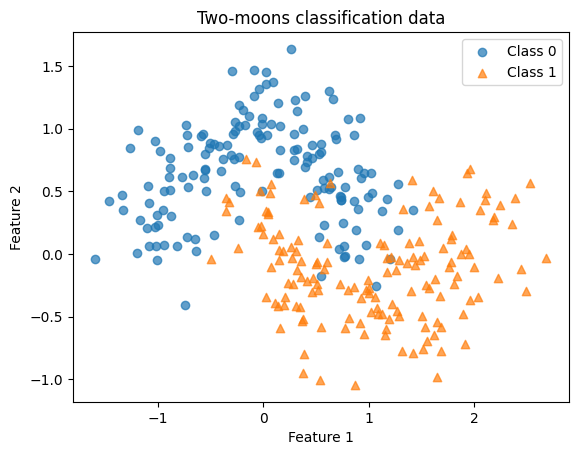

In [4]:
#Generate and plot the points
X, y = make_moons(n_samples=300, noise=0.25,
random_state=42)
print("Input shape:", X.shape)
print("Class counts:", np.bincount(y))
for label, marker in [(0, "o"), (1, "^")]:
  plt.scatter(X[y == label, 0], X[y == label, 1],
  marker=marker, label=f"Class {label}",
  alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-moons classification data")
plt.legend()
plt.show()

##Split the data and train one stump

In [5]:
#make the same split for every model
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev,random_state=42)
print("Train / validation / test rows:",len(y_train), len(y_val), len(y_test))

Train / validation / test rows: 180 60 60


In [6]:
stump = DecisionTreeClassifier(max_depth=1,
random_state=42)
stump.fit(X_train, y_train)
stump_train = accuracy_score(
y_train, stump.predict(X_train))
stump_val = accuracy_score(y_val, stump.predict(X_val))
print("Training accuracy:", round(stump_train, 3))
print("Validation accuracy:", round(stump_val, 3))

Training accuracy: 0.844
Validation accuracy: 0.783


##Train an ensemble of decision stumps
AdaBoost fits a sequence of weak learners. Here, each learner is a decision stump. We start with up to 50 learners and a learning rate of 0.5.

In [9]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),n_estimators=50, learning_rate=0.5,random_state=42)
ada.fit(X_train, y_train)
ada_val_pred = ada.predict(X_val)
ada_train = accuracy_score(y_train, ada.predict(X_train))
ada_val = accuracy_score(y_val, ada_val_pred)
print("Training accuracy:", round(ada_train, 3))
print("Validation accuracy:", round(ada_val, 3))
print("Learners fitted:", len(ada.estimators_))

Training accuracy: 0.972
Validation accuracy: 0.883
Learners fitted: 50
